# Importing Necessary Libraries

In [1]:
from tensorflow.keras.datasets import mnist
import  matplotlib.pyplot as plt
import numpy as np

ModuleNotFoundError: No module named 'tensorflow'

# Load the Data

In [2]:
(X_train,y_train),(X_test,y_test) = mnist.load_data()

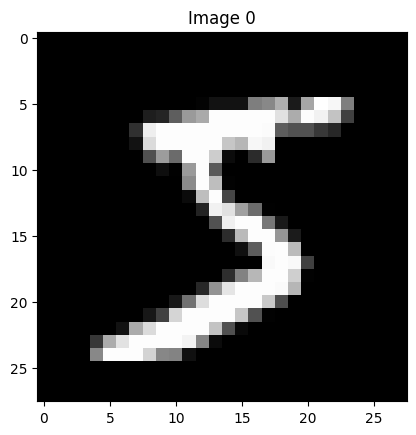

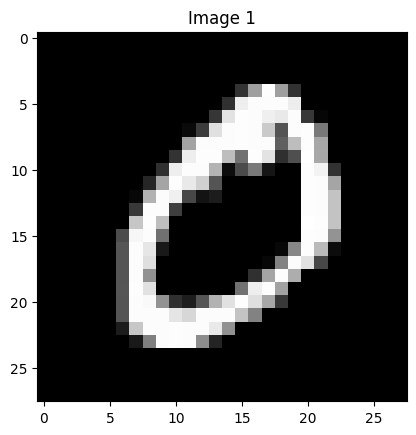

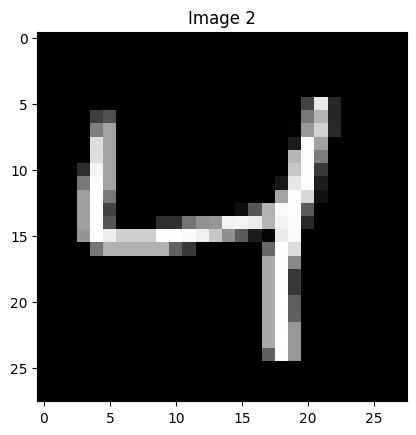

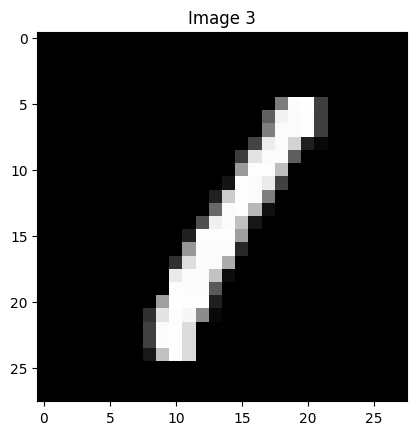

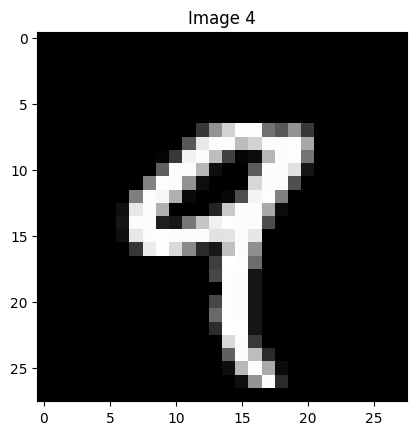

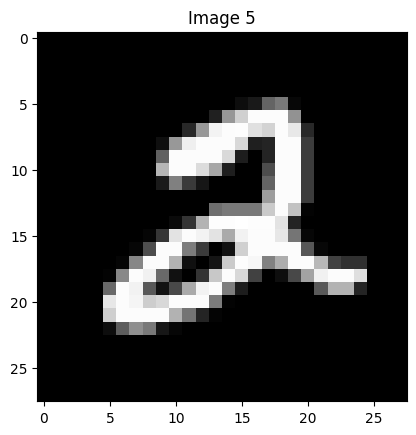

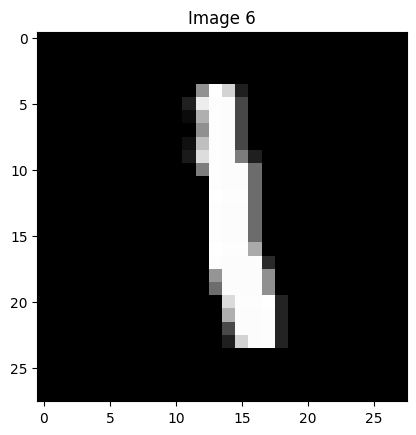

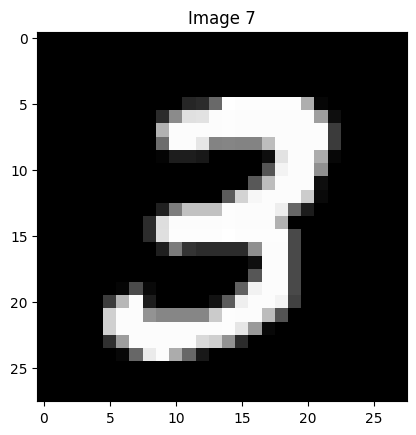

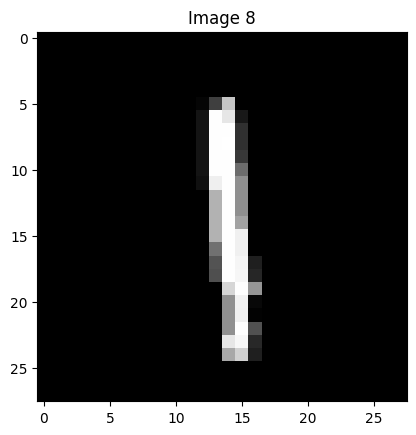

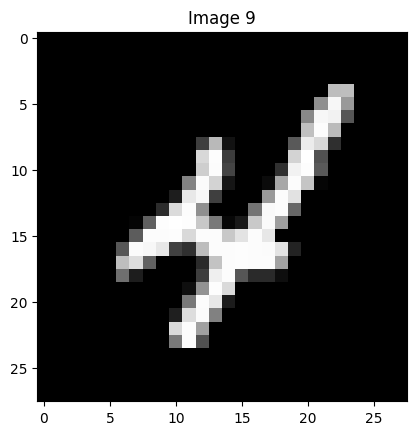

In [5]:
for i in range(10):
    plt.title(f"Image {i}")
    plt.imshow(X_train[i],cmap="gray")
    plt.show()

# Reshape the data

- **X_train** - > Actual Shape (60000,28,28)
- **X_train** - > After Flattening (60000,784)

In [7]:
X_train = X_train.reshape(-1,784)
X_test = X_test.reshape(-1,784)

# Normalize the data

- The dataset contains values ranging from 0 to 255 (0-absoulute black, 255-absolute white)
- **Why?** Reduces the risk of Overflow

In [8]:
X_train = X_train/255.0
X_test = X_test/255.0

# One Hot Ecnoding

- **Why Encode?** = > *Numerical Representation for Computation*
  
Neural networks operate on numerical data. Encoding transforms categorical or symbolic data (like labels or text) into numbers so the model can process it.

For example, class labels like "cat", "dog", "bird" are often converted using one-hot encoding into vectors like `[1,0,0]`, `[0,1,0]`, etc.


- **np.zeros((rows,cols))** => creates a zero matrix of given shape.
- **np.arange(shape)** => Generates evenly spaced values.

  **Example:** np.arange(3) = > `[0,1,2]`

**`out[np.arange(y.size),y]`** => out[[0,1,2...],[5,0,4...]] = 1 ---> this means 

```python
out[0,5] = 1
out[1,0]=1
out[2,4] = 1
    .
    .
    .
    .
    .
```

In [9]:
def one_hot(y,num_classes=10):
    out = np.zeros((y.size,num_classes))
    out[np.arange(y.size),y] = 1
    return out

# Reduce the Training Size(optional)

In [11]:
X = X_train[:30000]
y = one_hot(y_train[:30000],num_classes=10)

# Intialize Weights 

- **np.random.randn()** => generates values between (-0.5,0.5)

In [12]:
W1 = np.random.randn(784,128)
b1 = np.zeros((1,128))
W2 = np.random.randn(128,10)
b2 = np.zeros((1,10))

In [13]:
epochs,losses = [],[]

# Activation Function(s)



**Sigmoid Function :**  *output between 0 and 1*

$$
\sigma(x) = \frac{1}{1 + e^{-x}}
$$



**Tanh Function :** *Output between -1 and 1*

$$
\tanh(x) = \frac{e^x - e^{-x}}{e^x + e^{-x}}
$$



**ReLU(rectified linear unit) Function :**  *Simple, fast, sparse activation.  Outputs maximum(0 or number)*

$$
f(x) = \max(0, x)
$$

**Piecewise Notation for ReLU :**
$$
f(x) =
\begin{cases}
0 & \text{if } x \leq 0 \\
x & \text{if } x > 0
\end{cases}
$$


**Softmax Function :** *ouputs the probabilities of classes*

$$
f(z_i) = \frac{e^{z_i}}{\sum_{j=1}^{C} e^{z_j}}
$$

- \( z_i \): the logit (raw score) for class \( i \)  
- \( C \): total number of classes  
- Output: a probability distribution over all classes





In [14]:
def ReLU(Z):
    return np.maximum(0,Z)

def deriv_ReLU(Z):
    return Z>0

## Neural Network Training Process

Training a neural network involves adjusting weights and biases to minimize the loss function using **gradient descent**. This is done through **forward propagation**, **loss computation**, and **backpropagation**.

---

### Forward Propagation

1. Compute hidden layer:
   

$$
   Z_1 = X \cdot W_1 + b_1
$$


   

$$
   A_1 = \text{ReLU}(Z_1)
$$

### What is a Linear Transformation?

The operation
$$
Z_1 = XW_1 + b_1
$$
is called a linear transformation.

It means we’re applying a weighted sum of the inputs — each input feature contributes linearly to the output:

$$
Z_1^{(i)} = w_1x_1 + w_2x_2 + \dots + w_nx_n + b
$$

Geometrically, a linear transformation:

Scales, rotates, or shifts the input space,

But cannot bend or curve it — everything remains on a straight plane.

This is why linear models (like simple regression) can only draw straight-line decision boundaries.

### Why Do We Need an Activation Function?

If we only stacked linear transformations, say:

$$
X \rightarrow XW_1 + b_1 \rightarrow (XW_1 + b_1)W_2 + b_2
$$

…it would still be linear overall (you could rewrite it as one big matrix multiplication).
That means no matter how many layers you add, the model could only learn straight lines — not curves, not complex shapes.

That’s where activation functions like ReLU, Sigmoid, or tanh come in.

They:

Introduce non-linearity into the network,

Allow the model to learn complex, curved decision boundaries,

And help it capture intricate relationships between inputs and outputs.

So after the linear step ( Z_1 = XW_1 + b_1 ),
we apply a non-linear activation:

$$
A_1 = \text{ReLU}(Z_1)
$$

ReLU (Rectified Linear Unit) works as:
$$
\text{ReLU}(z) = \max(0, z)
$$
It keeps positive values and zeros out negatives — simple yet powerful, helping deep networks train faster and avoid vanishing gradients.

**In short:**

The linear transformation learns how much each input matters.

The activation decides whether that information should pass through.

Together, they allow the network to approximate any complex function — not just straight lines.


2. Compute output layer:
   

$$
   Z_2 = A_1 \cdot W_2 + b_2
$$


   

$$
   P = \text{Softmax}(Z_2)
$$



---

### Categorical Cross-Entropy Loss

Used for multi-class classification:


$$
\mathcal{L} = -\frac{1}{N} \sum_{i=1}^{N} \sum_{j=1}^{C} y_{ij} \cdot \log(p_{ij} + \epsilon)
$$



- \( y_{ij} \): true label (one-hot encoded)
- \( p_{ij} \): predicted probability
- \( epsilon \): small constant to avoid log(0)

---

### Backpropagation via Chain Rule

We compute gradients to update weights:

1. **Output layer gradient**:
   

$$
   dZ_2 = \frac{P - Y}{N}
$$


   

$$
   dW_2 = A_1^T \cdot dZ_2
$$


   

$$
   db_2 = \sum dZ_2
$$



2. **Hidden layer gradient**:
   

$$
   dA_1 = dZ_2 \cdot W_2^T
$$


   

$$
   dZ_1 = dA_1 \cdot \text{ReLU}'(Z_1)
$$


   

$$
   dW_1 = X^T \cdot dZ_1
   $$


   

$$
   db_1 = \sum dZ_1
$$



---

### Weight Update Rule

Using learning rate \( \alpha \):


$$
W_1 = W_1 - \alpha \cdot dW_1
$$




$$
b_1 = b_1 - \alpha \cdot db_1
$$




$$
W_2 = W_2 - \alpha \cdot dW_2
$$




$$
b_2 = b_2 - \alpha \cdot db_2
$$



---

This process is repeated for multiple epochs until the loss converges.

---

### Backpropagation Pattern for Multi-Layer ANN

### Output Layer

$$
dZ^{[L]} = A^{[L]} - Y
$$

$$
dW^{[L]} = (A^{[L-1]})^\top dZ^{[L]}
$$

$$
db^{[L]} = \sum_i dZ_i^{[L]}
$$

---

### Hidden Layers (for any layer ( l ))

1. **Get gradient flowing back from the next layer:**
   $$
   dA^{[l]} = dZ^{[l+1]} (W^{[l+1]})^\top
   $$

2. **Apply activation derivative to turn ( dA ) into ( dZ ):**
   $$
   dZ^{[l]} = dA^{[l]} \odot f'(Z^{[l]})
   $$

3. **Compute weight and bias gradients:**
   $$
   dW^{[l]} = (A^{[l-1]})^\top dZ^{[l]}
    $$

   $$
   db^{[l]} = \sum_i dZ_i^{[l]}
   $$

---

**Summary:**

* For the **output layer**, you directly get
  $$
  dZ = A - Y
  $$
  from the loss.

* For **each hidden layer**, you must first find
  $$
  dA = dZ_{\text{next}} W_{\text{next}}^\top
  $$
  then use your activation derivative to compute
    $$
  dZ = dA \odot f'(Z)
  $$
  before finding ( dW ) and ( db ).

This process repeats backward through every layer — that’s the **chain rule in action** across the network.



In [15]:
for epoch in range(2000):
    Z1 = X@W1 +b1
    A1 = ReLU(Z1)
    Z2 = A1@W2+b2
    e = np.exp(Z2-np.max(Z2,axis=1,keepdims=True))
    P = e/e.sum(axis=1,keepdims=True)
    loss = -np.mean(np.sum(y*np.log(P+1e-8),axis=1,keepdims=True))

    dZ2 = (P - y)/len(X)
    dW2 = A1.T@dZ2
    db2 = np.sum(dZ2,axis=0,keepdims=True)
    dA1 = dZ2@W2.T
    dZ1 = dA1 * deriv_ReLU(Z1)
    dW1 = X.T@dZ1
    db1 = np.sum(dZ1,axis=0,keepdims=True)

    W1-=0.1*dW1
    b1-=0.1*db1
    W2-=0.1*dW2
    b2-=0.1*db2

    epochs.append(epoch)
    losses.append(loss)

    if epoch%100 ==0:
        print(f"Epoch : {epoch} Loss: {loss:.4f}")
    

Epoch : 0 Loss: 16.1772
Epoch : 100 Loss: 2.4841
Epoch : 200 Loss: 1.8439
Epoch : 300 Loss: 1.5469
Epoch : 400 Loss: 1.3519
Epoch : 500 Loss: 1.2079
Epoch : 600 Loss: 1.0935
Epoch : 700 Loss: 0.9991
Epoch : 800 Loss: 0.9188
Epoch : 900 Loss: 0.8501
Epoch : 1000 Loss: 0.7899
Epoch : 1100 Loss: 0.7363
Epoch : 1200 Loss: 0.6889
Epoch : 1300 Loss: 0.6466
Epoch : 1400 Loss: 0.6085
Epoch : 1500 Loss: 0.5742
Epoch : 1600 Loss: 0.5432
Epoch : 1700 Loss: 0.5152
Epoch : 1800 Loss: 0.4899
Epoch : 1900 Loss: 0.4668


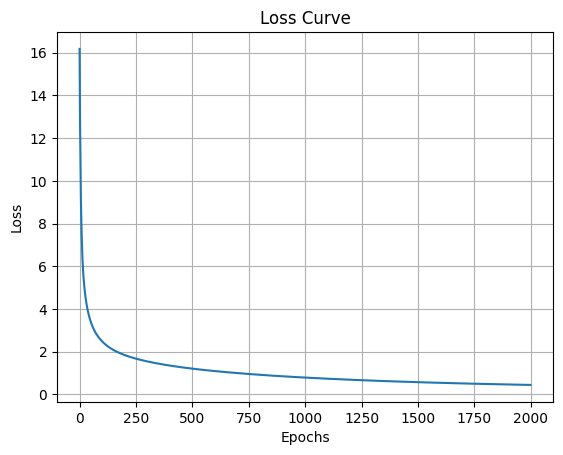

In [17]:
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.plot(epochs,losses)
plt.title("Loss Curve")
plt.grid(True)
plt.show()

In [19]:
y_test = one_hot(y_test,num_classes=10)

In [23]:
Z1 = X_test@W1+b1
A1 = ReLU(Z1)
Z2 = A1@W2+b2
e = np.exp(Z2-np.max(Z2,axis=1,keepdims=True))
P = e/e.sum(axis=1,keepdims=True)

y_pred = np.argmax(P,axis=1,keepdims=True)
y_true = np.argmax(y_test,axis=1,keepdims=True)

acc=np.mean(y_pred == y_true)

print(f"Accuracy: {acc * 100:.2f}")

Accuracy: 90.49


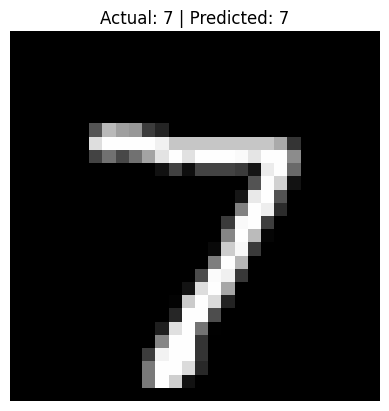

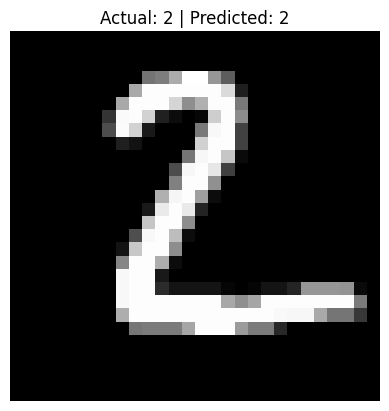

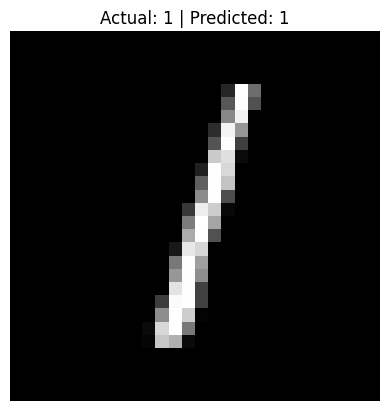

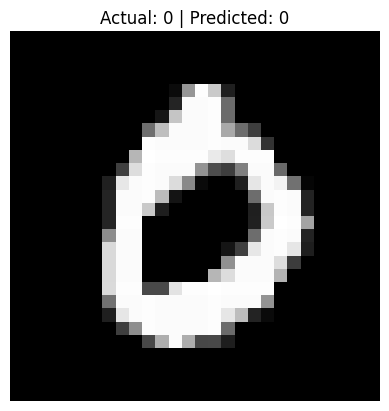

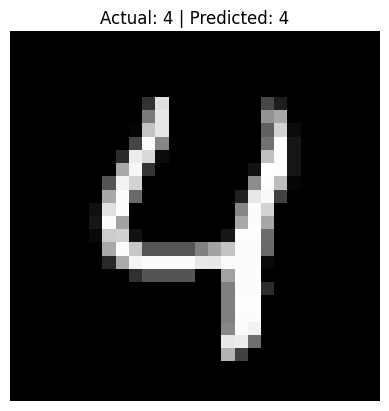

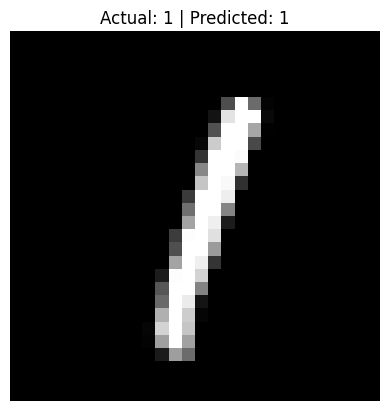

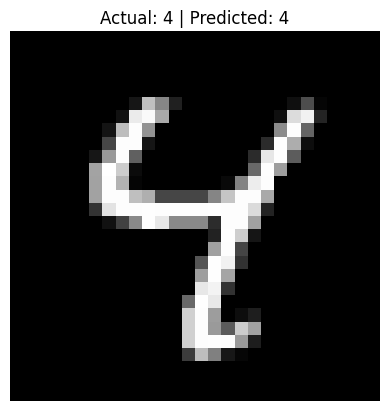

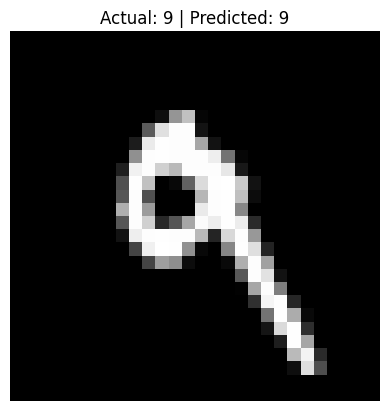

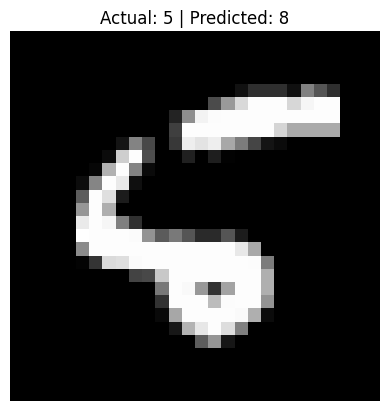

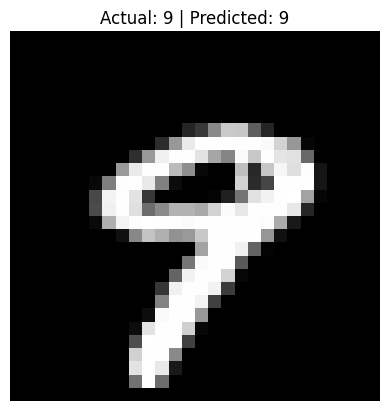

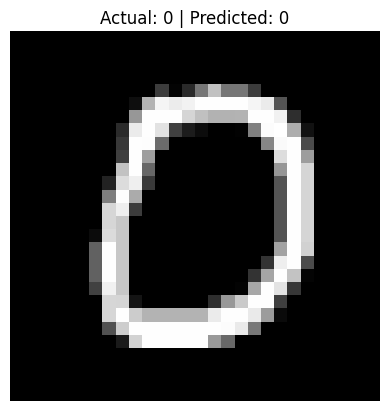

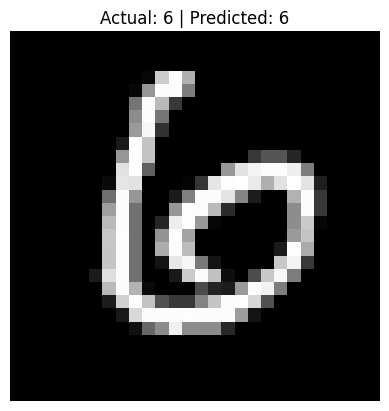

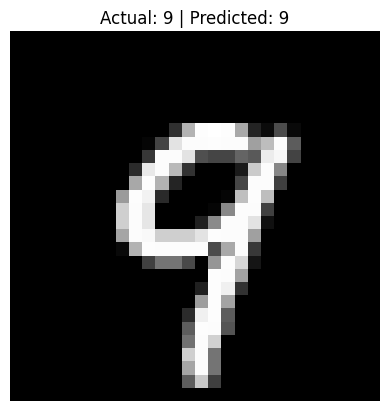

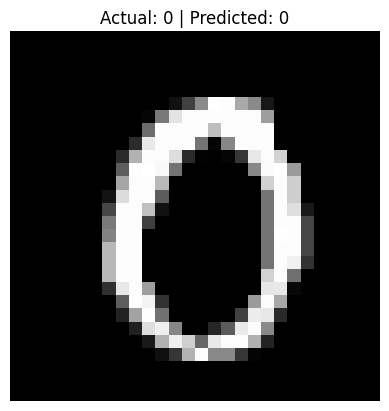

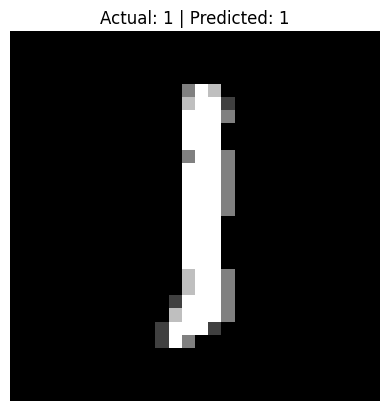

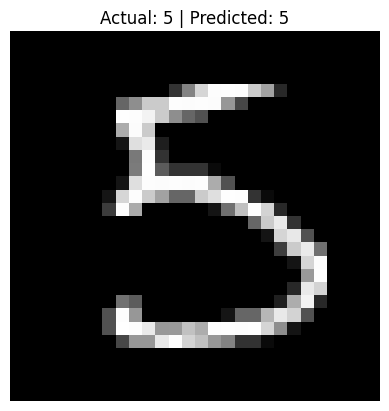

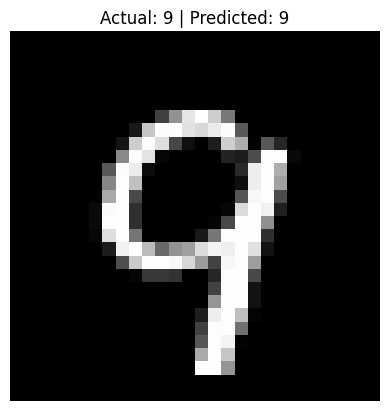

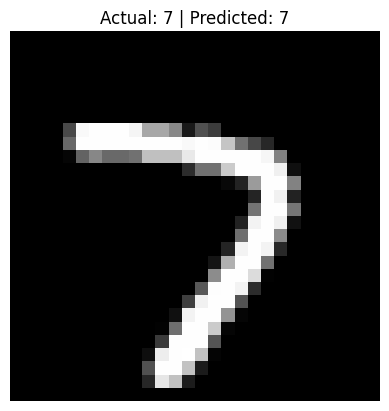

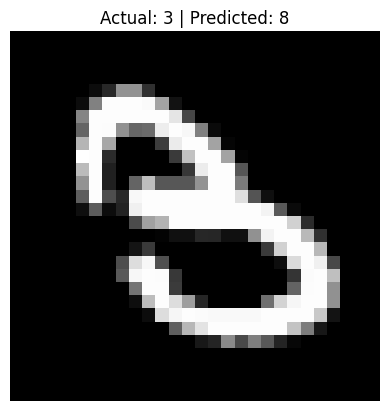

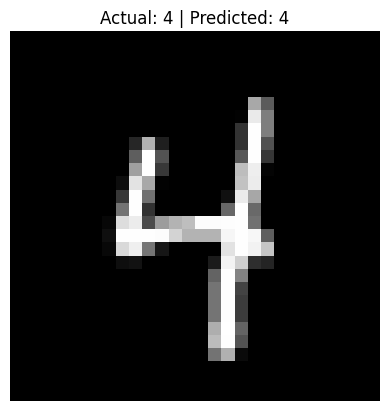

In [26]:
for i in range(20):
    plt.title(f"Image {i}")
    plt.imshow(X_test[i].reshape(28,28),cmap='gray')
    plt.title(f"Actual: {y_true[i][0]} | Predicted: {y_pred[i][0]}")
    plt.axis("off")
    plt.show()